# 3D Helmholtz PFDM — proposed numerics-informed hyperparameters

We consider
\[
(-\Delta+\kappa^2)u=f,\qquad u|_{\partial\Omega}=0,
\]
on \(\Omega=(0,1)^3\), with a fixed training resolution \(N_x=5\).

This notebook focuses only on the proposed PFDM and its hyperparameter selection:
\[
\tau=2,\qquad
\sigma_f=\|u_h\|_\infty,\qquad
C=\widehat C_{\rm defect},
\]
and
\[
\ell\in h\{0.5,0.75,1,1.5,2\}
\]
is selected by log marginal likelihood.  Computational-cost comparisons are intentionally omitted.

In [1]:
using LinearAlgebra
using SparseArrays
using FFTW
using SpecialFunctions
using IterativeSolvers
using LinearMaps
using Plots
using Statistics
using Printf


In [2]:
# 3次元 Matérnカーネル（入力 x1, x2 ∈ R³）
function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

# 3D observation matrix on the FULL grid, including boundaries.
#
# Boundary rows: u = 0 exactly  -> identity row
# Interior rows: (-Delta_h + k^2 I)u = f
#
# This is the direct 3D analogue of the 1D construction
#   Sigma_diag = [0, interior noise..., 0].
function build_H_3d_helmholtz_full(Nx, h, k)
    # Nx = number of INTERIOR points per coordinate direction.
    nside = Nx + 2
    Nall  = nside^3

    index(i,j,l) = i + (j-1)*nside + (l-1)*nside^2

    rows = Int[]
    cols = Int[]
    vals = Float64[]
    is_boundary = falses(Nall)

    for l in 1:nside, j in 1:nside, i in 1:nside
        q = index(i,j,l)

        bdry = (i == 1 || i == nside ||
                j == 1 || j == nside ||
                l == 1 || l == nside)

        is_boundary[q] = bdry

        if bdry
            # Exact homogeneous Dirichlet condition.
            push!(rows,q); push!(cols,q); push!(vals,1.0)
        else
            # Helmholtz PDE row on an interior point.
            push!(rows,q); push!(cols,q); push!(vals,6.0/h^2 + k^2)
            push!(rows,q); push!(cols,index(i-1,j,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i+1,j,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j-1,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j+1,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j,l-1)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j,l+1)); push!(vals,-1.0/h^2)
        end
    end

    H = sparse(rows,cols,vals,Nall,Nall)
    return H, is_boundary
end

# Observation vector on the full grid:
# boundary -> 0, interior -> f.
function make_y_3d_full(xfull, k, is_boundary)
    y = zeros(length(xfull))
    for q in eachindex(xfull)
        if !is_boundary[q]
            x,yq,z = xfull[q]
            y[q] = f_func(x,yq,z,k)
        end
    end
    return y
end

# BTTTB セットアップ: 3D循環埋め込み + 3D FFT
function btttb_fft_setup(k_col_arr, Nx, Ny, Nz)
    # k_col_arr[i,j,l] = k(x1, x_{i,j,l}) for i in 1:Nx, j in 1:Ny, l in 1:Nz
    C = zeros(2Nx, 2Ny, 2Nz)
    C[1:Nx, 1:Ny, 1:Nz] .= k_col_arr
    # x方向の折り返し
    Nx > 1 && (C[Nx+2:2Nx, 1:Ny, 1:Nz] .= k_col_arr[Nx:-1:2, :, :])
    # y方向の折り返し
    Ny > 1 && (C[1:Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[:, Ny:-1:2, :])
    # z方向の折り返し
    Nz > 1 && (C[1:Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[:, :, Nz:-1:2])
    # xy折り返し
    Nx > 1 && Ny > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, :])
    # xz折り返し
    Nx > 1 && Nz > 1 && (C[Nx+2:2Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, :, Nz:-1:2])
    # yz折り返し
    Ny > 1 && Nz > 1 && (C[1:Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[:, Ny:-1:2, Nz:-1:2])
    # xyz折り返し
    Nx > 1 && Ny > 1 && Nz > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, Nz:-1:2])
    return fft(fft(fft(C, 1), 2), 3)
end

function btttb_matvec(k_fft3, v, Nx, Ny, Nz)
    V     = reshape(v, Nx, Ny, Nz)
    V_pad = zeros(2Nx, 2Ny, 2Nz)
    V_pad[1:Nx, 1:Ny, 1:Nz] .= V
    result = real.(ifft(ifft(ifft(
        fft(fft(fft(V_pad, 1), 2), 3) .* k_fft3,
    1), 2), 3))
    return vec(result[1:Nx, 1:Ny, 1:Nz])
end

# 真の解・右辺: -Δu + k^2*u = f
# u(x,y,z) = sin(πx)sin(πy)sin(πz) → (-Δ+k^2)u = (3π^2+k^2)u
u_exact(x, y, z, k) = sin(π*x) * sin(π*y) * sin(π*z)
f_func(x, y, z, k)  = (3π^2 + k^2) * sin(π*x) * sin(π*y) * sin(π*z)


f_func (generic function with 1 method)

In [3]:
# ============================================================
# Fixed problem / FULL training grid, including boundaries
# ============================================================

Nx = 5                       # number of INTERIOR points per axis
ν_fixed = 1.5
τ_fixed = 2
p_order = 2
k_wave  = 1.0

h = 1.0 / (Nx + 1)
nside = Nx + 2

# Full grid contains x=0 and x=1 (and similarly for y,z).
xs_full = collect(range(0.0,1.0,length=nside))
ys_full = copy(xs_full)
zs_full = copy(xs_full)

X_full = [[x,y,z] for z in zs_full for y in ys_full for x in xs_full]
N_full = length(X_full)

H, is_boundary = build_H_3d_helmholtz_full(Nx,h,k_wave)
y_obs = make_y_3d_full(X_full,k_wave,is_boundary)

# Noise-free boundary rows, noisy interior PDE rows.
# This is the 3D analogue of
# Sigma_diag = vcat([0.0], fill(noise_var,...), [0.0]).
interior_idx = findall(.!is_boundary)
boundary_idx = findall(is_boundary)

# Deterministic FDM solve on the same full system.
# Boundary values are exactly zero because boundary rows are identity.
u_fdm_full = H \ y_obs

# Extract the interior cube for C calibration and diagnostics.
U_fdm_full = reshape(u_fdm_full,nside,nside,nside)
u_fdm = vec(U_fdm_full[2:end-1,2:end-1,2:end-1])

xs = xs_full[2:end-1]
ys = ys_full[2:end-1]
zs = zs_full[2:end-1]

u_true_train = [u_exact(x,y,z,k_wave) for z in zs for y in ys for x in xs]

@printf("Nx(interior)=%d, full grid=%d^3=%d, h=%.6g\n",Nx,nside,N_full,h)
@printf("# boundary points = %d\n",length(boundary_idx))
@printf("# interior points = %d\n",length(interior_idx))
@printf("max |FDM boundary value| = %.3e\n",maximum(abs.(u_fdm_full[boundary_idx])))
@printf("FDM interior Linf error = %.6g\n",maximum(abs.(u_fdm-u_true_train)))


Nx(interior)=5, full grid=7^3=343, h=0.166667
# boundary points = 218
# interior points = 125
max |FDM boundary value| = 0.000e+00
FDM interior Linf error = 0.0223892


In [4]:
# ============================================================
# Coarsening-defect estimator for C
#
# Uses the same target-grid FDM solution u_h only.
# No h/2 solve is required.
# ============================================================

function estimate_C_coarsening_3d(u_h, h, Nx; p=2, k_wave=1.0)
    U = reshape(u_h, Nx, Nx, Nx)

    # Homogeneous Dirichlet boundary extension
    function uval(i,j,k)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           k == 0 || k == Nx+1
            return 0.0
        elseif 1 <= i <= Nx && 1 <= j <= Nx && 1 <= k <= Nx
            return U[i,j,k]
        else
            error("2h stencil left the domain")
        end
    end

    c_hat = Float64[]
    defect = Float64[]

    # i,j,k = 2,...,Nx-1 allows ±2 to hit the exact boundary
    for k in 2:(Nx-1), j in 2:(Nx-1), i in 2:(Nx-1)
        x = i*h; y = j*h; z = k*h

        D2h_u = (
            6*uval(i,j,k)
            - uval(i-2,j,k) - uval(i+2,j,k)
            - uval(i,j-2,k) - uval(i,j+2,k)
            - uval(i,j,k-2) - uval(i,j,k+2)
        )/(2h)^2 + k_wave^2*uval(i,j,k)

        d = D2h_u - f_func(x,y,z,k_wave)
        c = d / ((2.0^p - 1.0)*h^p)

        push!(defect,d)
        push!(c_hat,c)
    end

    C_hat = mean(c_hat.^2)
    return C_hat, c_hat, defect
end

C_hat, c_hat, defect = estimate_C_coarsening_3d(
    u_fdm, h, Nx;
    p=p_order,
    k_wave=k_wave
)

sigma_f = maximum(abs.(u_fdm))  # same as full-grid max because boundary values are zero

println("=== Numerics-informed calibration ===")
@printf("tau        = %d\n", τ_fixed)
@printf("sigma_f    = %.6g  [||u_h||_inf]\n", sigma_f)
@printf("C_hat      = %.6g\n", C_hat)
@printf("RMS(c_hat) = %.6g\n", sqrt(mean(c_hat.^2)))
@printf("defect pts = %d\n", length(c_hat))


=== Numerics-informed calibration ===
tau        = 2
sigma_f    = 1.02239  [||u_h||_inf]
C_hat      = 327.332
RMS(c_hat) = 18.0923
defect pts = 27


In [5]:
# ============================================================
# ell selection: small h-scaled LML grid
# Exact Dirichlet boundary conditioning is included in the LML.
# ============================================================

function log_marginal_3d_full(
    X_full,y_obs,H,is_boundary;
    ν,ell,sigma_f,C,tau,h,jitter=1e-10
)
    Nall = length(y_obs)
    noise_var = C*h^(2tau)

    Sigma_diag = [is_boundary[q] ? 0.0 : noise_var for q in 1:Nall]

    K = [
        matern_kernel_3d(X_full[i],X_full[j]; ν=ν, ℓ=ell, σf=sigma_f)
        for i in 1:Nall, j in 1:Nall
    ]

    A = Hermitian(
        H*K*H' +
        Diagonal(Sigma_diag) +
        jitter*I
    )

    L = cholesky(A)
    α = L \ y_obs

    return -0.5*dot(y_obs,α) -
           sum(log,diag(L.L)) -
           0.5*Nall*log(2π)
end

ell_factors = [0.5,0.75,1.0,1.5,2.0]
ell_grid = h .* ell_factors
scores = fill(-Inf,length(ell_grid))

for (i,ell) in enumerate(ell_grid)
    scores[i] = log_marginal_3d_full(
        X_full,y_obs,H,is_boundary;
        ν=ν_fixed,
        ell=ell,
        sigma_f=sigma_f,
        C=C_hat,
        tau=τ_fixed,
        h=h
    )
end

best_idx = argmax(scores)
best_ell = ell_grid[best_idx]

println("\n=== Length-scale grid search ===")
@printf("%-12s %-12s %-18s\n","ell/h","ell","log marginal")
println("-"^44)
for (fac,ell,s) in zip(ell_factors,ell_grid,scores)
    @printf("%-12.3f %-12.6g %-18.6f\n",fac,ell,s)
end
println("-"^44)
@printf("selected ell = %.6g  (ell/h=%.3f)\n",best_ell,best_ell/h)



=== Length-scale grid search ===
ell/h        ell          log marginal      
--------------------------------------------
0.500        0.0833333    -982.310560       
0.750        0.125        -942.240664       
1.000        0.166667     -887.654877       
1.500        0.25         -772.779509       
2.000        0.333333     -669.242497       
--------------------------------------------
selected ell = 0.333333  (ell/h=2.000)


In [6]:
# ============================================================
# PFDM posterior on a fine 3D test grid INCLUDING boundaries
# ============================================================

Nx_test = 31                 # interior test points per axis
nside_test = Nx_test + 2     # plus the two boundary locations

xt = collect(range(0.0,1.0,length=nside_test))
yt = copy(xt)
zt = copy(xt)

X_test = [[x,y,z] for z in zt for y in yt for x in xt]
N_test = length(X_test)

u_true_test = [u_exact(x,y,z,k_wave) for z in zt for y in yt for x in xt]

K = [
    matern_kernel_3d(X_full[i],X_full[j]; ν=ν_fixed, ℓ=best_ell, σf=sigma_f)
    for i in 1:N_full, j in 1:N_full
]

K_star = [
    matern_kernel_3d(X_test[i],X_full[j]; ν=ν_fixed, ℓ=best_ell, σf=sigma_f)
    for i in 1:N_test, j in 1:N_full
]

noise_var = C_hat*h^(2τ_fixed)
Sigma_diag = [is_boundary[q] ? 0.0 : noise_var for q in 1:N_full]

A = Hermitian(
    H*K*H' +
    Diagonal(Sigma_diag) +
    1e-10*I
)

L = cholesky(A)
α = L \ y_obs

# Cov(u_*, observations) = K_* H'
Ks = K_star*H'
mu_test = Ks*α

W = L.L \ Ks'
var_test = sigma_f^2 .- vec(sum(W.^2,dims=1))
std_test = sqrt.(max.(var_test,0.0))

# Test-grid boundary mask, for diagnostics only.
function is_test_boundary(x,y,z)
    return x == 0.0 || x == 1.0 ||
           y == 0.0 || y == 1.0 ||
           z == 0.0 || z == 1.0
end

test_boundary = [is_test_boundary(x,y,z) for z in zt for y in yt for x in xt]

err = u_true_test .- mu_test
abs_err = abs.(err)

rmse = sqrt(mean(err.^2))
linf = maximum(abs_err)
coverage = mean(abs_err .<= 1.96 .* std_test)
mean_std = mean(std_test)
mean_ci  = mean(1.96 .* std_test)

println("\n=== Fine-test metrics with exact boundary conditioning ===")
@printf("Nx_train interior = %d\n",Nx)
@printf("Nx_test interior  = %d\n",Nx_test)
@printf("ell      = %.6g\n",best_ell)
@printf("sigma_f  = %.6g\n",sigma_f)
@printf("C_hat    = %.6g\n",C_hat)
@printf("RMSE     = %.6g\n",rmse)
@printf("Linf     = %.6g\n",linf)
@printf("coverage = %.3f\n",coverage)
@printf("mean std = %.6g\n",mean_std)
@printf("mean 95%% half-width = %.6g\n",mean_ci)
@printf("max |posterior mean| on boundary = %.3e\n",maximum(abs.(mu_test[test_boundary])))
@printf("max posterior std on boundary    = %.3e\n",maximum(std_test[test_boundary]))



=== Fine-test metrics with exact boundary conditioning ===
Nx_train interior = 5
Nx_test interior  = 31
ell      = 0.333333
sigma_f  = 1.02239
C_hat    = 327.332
RMSE     = 0.00973072
Linf     = 0.0223606
coverage = 1.000
mean std = 0.175539
mean 95% half-width = 0.344056
max |posterior mean| on boundary = 3.405e-03
max posterior std on boundary    = 2.081e-01


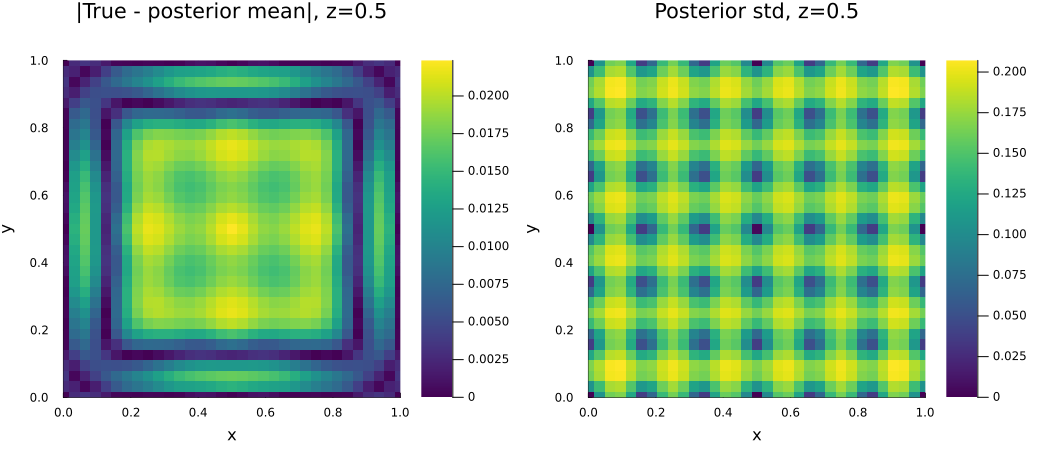

"/Users/shoji/Project_with_Jon/Helmholtz_arranged/helmholtz3d_proposed_error_std_exact_boundary.png"

In [7]:
# ============================================================
# Paper-style middle-z slice
#   left : |True - posterior mean|
#   right: posterior std
# Separate color scales so both spatial structures are visible.
# ============================================================

U_true = reshape(u_true_test,nside_test,nside_test,nside_test)
U_mu   = reshape(mu_test,    nside_test,nside_test,nside_test)
U_std  = reshape(std_test,   nside_test,nside_test,nside_test)

zi = argmin(abs.(zt .- 0.5))
zval = zt[zi]

E = abs.(U_true[:,:,zi] .- U_mu[:,:,zi])
S = U_std[:,:,zi]

p1 = heatmap(
    xt,yt,E';
    title="|True - posterior mean|, z=$(round(zval,digits=3))",
    xlabel="x",ylabel="y",
    color=:viridis,
    clim=(0,maximum(E)),
    aspect_ratio=:equal,
    xlims=(0,1),ylims=(0,1)
)

p2 = heatmap(
    xt,yt,S';
    title="Posterior std, z=$(round(zval,digits=3))",
    xlabel="x",ylabel="y",
    color=:viridis,
    clim=(0,maximum(S)),
    aspect_ratio=:equal,
    xlims=(0,1),ylims=(0,1)
)

fig = plot(p1,p2; layout=(1,2), size=(1050,470), margin=3*Plots.mm)
display(fig)
savefig(fig,"helmholtz3d_proposed_error_std_exact_boundary.png")


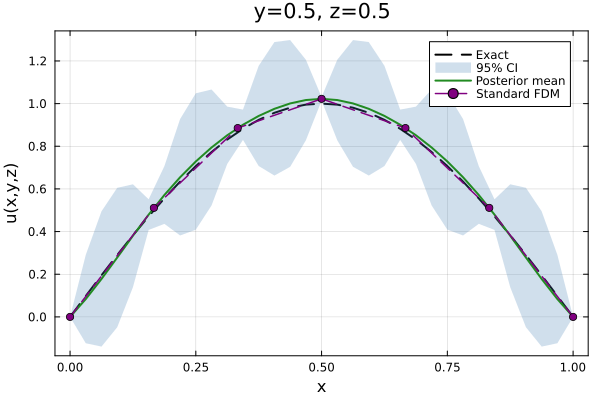

"/Users/shoji/Project_with_Jon/Helmholtz_arranged/helmholtz3d_proposed_centerline_exact_boundary.png"

In [8]:
# ============================================================
# Center-line solution / posterior mean / 95% CI
# Exact boundary observations are already included in posterior.
# ============================================================

yi = argmin(abs.(yt .- 0.5))
zi = argmin(abs.(zt .- 0.5))

yval = yt[yi]
zval = zt[zi]

U_true = reshape(u_true_test,nside_test,nside_test,nside_test)
U_mu   = reshape(mu_test,    nside_test,nside_test,nside_test)
U_std  = reshape(std_test,   nside_test,nside_test,nside_test)

utr = U_true[:,yi,zi]
umu = U_mu[:,yi,zi]
usd = U_std[:,yi,zi]

# FDM full-grid line already contains the exact boundary values.
yi_h = argmin(abs.(ys_full .- yval))
zi_h = argmin(abs.(zs_full .- zval))
u_fdm_line = U_fdm_full[:,yi_h,zi_h]

p = plot(
    xt,utr;
    label="Exact",lw=2,ls=:dash,color=:black,
    xlabel="x",ylabel="u(x,y,z)",
    title="y=$(round(yval,digits=3)), z=$(round(zval,digits=3))",
    framestyle=:box
)
plot!(p,xt,umu .+ 1.96.*usd;
    fillrange=umu .- 1.96.*usd,
    fillalpha=0.25,linealpha=0,label="95% CI",color=:steelblue)
plot!(p,xt,umu; label="Posterior mean",lw=2,color=:forestgreen)
plot!(p,xs_full,u_fdm_line; label="Standard FDM",lw=1.5,ls=:dash,
    marker=:circle,markersize=4,color=:purple)

display(p)
savefig(p,"helmholtz3d_proposed_centerline_exact_boundary.png")


### Boundary-conditioning check

This implementation uses the full Cartesian grid, including all six faces. Boundary rows of the observation matrix are identity rows and their noise variance is exactly zero. Interior Helmholtz rows use variance \(C h^{2\tau}\). Thus the GP posterior is directly conditioned on the homogeneous Dirichlet data, rather than merely inserting boundary values into the finite-difference stencil.

## Nx sweep

Repeat the exact-boundary, numerics-informed PFDM experiment for

\[
N_x\in\{4,5,6,8\}.
\]

For each case,

\[
\sigma_f=\|u_h\|_\infty,\qquad
C=\widehat C_{\rm defect},
\]

and \(\ell\) is selected from

\[
\ell/h\in\{0.5,0.75,1,1.5,2\}
\]

by marginal likelihood.


In [9]:
# ============================================================
# Nx sweep
# ============================================================

Nx_list = [4, 5, 6, 8]

Nx_test_sweep = 31
nside_test_sweep = Nx_test_sweep + 2

xt_sweep = collect(range(0.0,1.0,length=nside_test_sweep))
yt_sweep = copy(xt_sweep)
zt_sweep = copy(xt_sweep)

X_test_sweep = [
    [x,y,z]
    for z in zt_sweep
    for y in yt_sweep
    for x in xt_sweep
]

u_true_test_sweep = [
    u_exact(x,y,z,k_wave)
    for z in zt_sweep
    for y in yt_sweep
    for x in xt_sweep
]

N_test_sweep = length(X_test_sweep)

results_Nx = NamedTuple[]

for nx in Nx_list

    h_nx = 1.0 / (nx + 1)
    nside_nx = nx + 2

    xs_nx = collect(range(0.0,1.0,length=nside_nx))
    ys_nx = copy(xs_nx)
    zs_nx = copy(xs_nx)

    X_nx = [
        [x,y,z]
        for z in zs_nx
        for y in ys_nx
        for x in xs_nx
    ]

    N_nx = length(X_nx)

    H_nx, is_boundary_nx =
        build_H_3d_helmholtz_full(
            nx,
            h_nx,
            k_wave
        )

    y_nx =
        make_y_3d_full(
            X_nx,
            k_wave,
            is_boundary_nx
        )

    # deterministic FDM
    u_fdm_full_nx =
        H_nx \ y_nx

    U_fdm_full_nx =
        reshape(
            u_fdm_full_nx,
            nside_nx,
            nside_nx,
            nside_nx
        )

    u_fdm_nx =
        vec(
            U_fdm_full_nx[
                2:end-1,
                2:end-1,
                2:end-1
            ]
        )

    # numerics-informed sigma and C
    sigma_nx =
        maximum(abs.(u_fdm_nx))

    C_nx,
    c_hat_nx,
    defect_nx =
        estimate_C_coarsening_3d(
            u_fdm_nx,
            h_nx,
            nx;
            p=p_order,
            k_wave=k_wave
        )

    # ell grid search
    ell_grid_nx =
        h_nx .* ell_factors

    scores_nx =
        fill(-Inf,length(ell_grid_nx))

    for (i,ell_nx) in enumerate(ell_grid_nx)

        scores_nx[i] =
            log_marginal_3d_full(
                X_nx,
                y_nx,
                H_nx,
                is_boundary_nx;
                ν=ν_fixed,
                ell=ell_nx,
                sigma_f=sigma_nx,
                C=C_nx,
                tau=τ_fixed,
                h=h_nx
            )
    end

    ibest =
        argmax(scores_nx)

    ell_nx =
        ell_grid_nx[ibest]

    # prior covariance
    K_nx = [
        matern_kernel_3d(
            X_nx[i],
            X_nx[j];
            ν=ν_fixed,
            ℓ=ell_nx,
            σf=sigma_nx
        )
        for i in 1:N_nx,
            j in 1:N_nx
    ]

    Kstar_nx = [
        matern_kernel_3d(
            X_test_sweep[i],
            X_nx[j];
            ν=ν_fixed,
            ℓ=ell_nx,
            σf=sigma_nx
        )
        for i in 1:N_test_sweep,
            j in 1:N_nx
    ]

    noise_var_nx =
        C_nx * h_nx^(2τ_fixed)

    Sigma_diag_nx = [
        is_boundary_nx[q] ?
        0.0 :
        noise_var_nx
        for q in 1:N_nx
    ]

    A_nx = Hermitian(
        H_nx*K_nx*H_nx' +
        Diagonal(Sigma_diag_nx) +
        1e-10*I
    )

    L_nx = cholesky(A_nx)
    alpha_nx = L_nx \ y_nx

    Ks_nx = Kstar_nx * H_nx'
    mu_nx = Ks_nx * alpha_nx

    W_nx = L_nx.L \ Ks_nx'
    var_nx =
        sigma_nx^2 .-
        vec(sum(W_nx.^2,dims=1))

    std_nx =
        sqrt.(max.(var_nx,0.0))

    err_nx =
        u_true_test_sweep .-
        mu_nx

    abs_err_nx =
        abs.(err_nx)

    rmse_nx =
        sqrt(mean(err_nx.^2))

    linf_nx =
        maximum(abs_err_nx)

    coverage_nx =
        mean(
            abs_err_nx .<=
            1.96 .* std_nx
        )

    mean_std_nx =
        mean(std_nx)

    push!(
        results_Nx,
        (
            Nx=nx,
            h=h_nx,
            ell=ell_nx,
            ell_over_h=ell_nx/h_nx,
            sigma_f=sigma_nx,
            C_hat=C_nx,
            ell_grid=ell_grid_nx,
            lml=scores_nx,
            mu=mu_nx,
            std=std_nx,
            abs_err=abs_err_nx,
            rmse=rmse_nx,
            linf=linf_nx,
            coverage=coverage_nx,
            mean_std=mean_std_nx
        )
    )

    @printf(
        "Nx=%d h=%.5f ell=%.5f ell/h=%.2f sigma=%.5g C=%.5g RMSE=%.5g Linf=%.5g coverage=%.3f\n",
        nx,
        h_nx,
        ell_nx,
        ell_nx/h_nx,
        sigma_nx,
        C_nx,
        rmse_nx,
        linf_nx,
        coverage_nx
    )
end


Nx=4 h=0.20000 ell=0.40000 ell/h=2.00 sigma=0.88813 C=409.92 RMSE=0.013918 Linf=0.037011 coverage=1.000
Nx=5 h=0.16667 ell=0.33333 ell/h=2.00 sigma=1.0224 C=327.33 RMSE=0.0097307 Linf=0.022361 coverage=1.000
Nx=6 h=0.14286 ell=0.28571 ell/h=2.00 sigma=0.94184 C=272.73 RMSE=0.0074139 Linf=0.02033 coverage=1.000
Nx=8 h=0.11111 ell=0.22222 ell/h=2.00 sigma=0.96455 C=208.73 RMSE=0.0046486 Linf=0.010414 coverage=1.000


In [10]:
# ============================================================
# Summary table
# ============================================================

println()
println("=== Nx sweep summary ===")

@printf(
    "%-5s %-9s %-10s %-8s %-11s %-12s %-10s %-10s %-10s %-10s\n",
    "Nx",
    "h",
    "ell",
    "ell/h",
    "sigma_f",
    "C_hat",
    "RMSE",
    "Linf",
    "coverage",
    "mean std"
)

println("-"^105)

for r in results_Nx
    @printf(
        "%-5d %-9.5f %-10.5f %-8.3f %-11.5g %-12.5g %-10.4g %-10.4g %-10.3f %-10.4g\n",
        r.Nx,
        r.h,
        r.ell,
        r.ell_over_h,
        r.sigma_f,
        r.C_hat,
        r.rmse,
        r.linf,
        r.coverage,
        r.mean_std
    )
end



=== Nx sweep summary ===
Nx    h         ell        ell/h    sigma_f     C_hat        RMSE       Linf       coverage   mean std  
---------------------------------------------------------------------------------------------------------
4     0.20000   0.40000    2.000    0.88813     409.92       0.01392    0.03701    1.000      0.1533    
5     0.16667   0.33333    2.000    1.0224      327.33       0.009731   0.02236    1.000      0.1755    
6     0.14286   0.28571    2.000    0.94184     272.73       0.007414   0.02033    1.000      0.1611    
8     0.11111   0.22222    2.000    0.96455     208.73       0.004649   0.01041    1.000      0.1642    


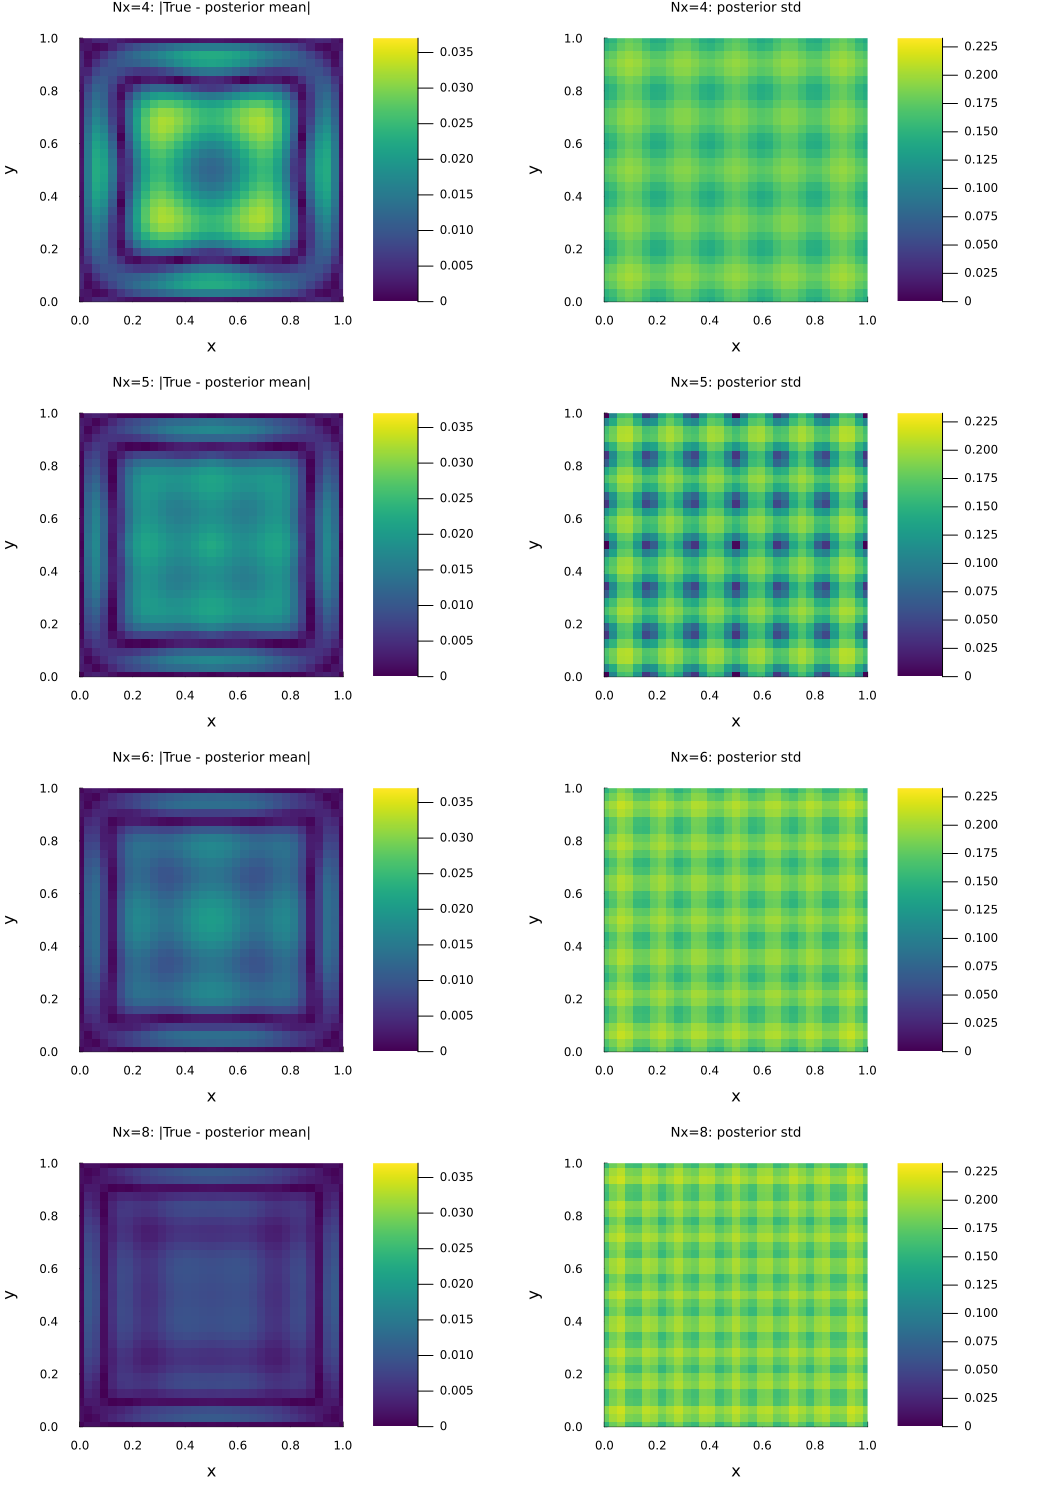

Saved: helmholtz3d_Nx_sweep_error_std.png


In [11]:
# ============================================================
# Middle-z heatmaps for each Nx
# Left: |True - posterior mean|
# Right: posterior std
# ============================================================

zi =
    argmin(abs.(zt_sweep .- 0.5))

Emax_all =
    maximum(
        maximum(r.abs_err)
        for r in results_Nx
    )

Smax_all =
    maximum(
        maximum(r.std)
        for r in results_Nx
    )

plots_Nx = []

for r in results_Nx

    E3 =
        reshape(
            r.abs_err,
            nside_test_sweep,
            nside_test_sweep,
            nside_test_sweep
        )

    S3 =
        reshape(
            r.std,
            nside_test_sweep,
            nside_test_sweep,
            nside_test_sweep
        )

    E = E3[:,:,zi]
    S = S3[:,:,zi]

    pE = heatmap(
        xt_sweep,
        yt_sweep,
        E';
        title="Nx=$(r.Nx): |True - posterior mean|",
        xlabel="x",
        ylabel="y",
        color=:viridis,
        clim=(0,Emax_all),
        aspect_ratio=:equal,
        xlims=(0,1),
        ylims=(0,1),
        titlefontsize=9
    )

    pS = heatmap(
        xt_sweep,
        yt_sweep,
        S';
        title="Nx=$(r.Nx): posterior std",
        xlabel="x",
        ylabel="y",
        color=:viridis,
        clim=(0,Smax_all),
        aspect_ratio=:equal,
        xlims=(0,1),
        ylims=(0,1),
        titlefontsize=9
    )

    push!(plots_Nx,pE)
    push!(plots_Nx,pS)
end

fig_Nx = plot(
    plots_Nx...;
    layout=(4,2),
    size=(1050,1500),
    margin=3*Plots.mm
)

display(fig_Nx)

savefig(
    fig_Nx,
    "helmholtz3d_Nx_sweep_error_std.png"
)

println("Saved: helmholtz3d_Nx_sweep_error_std.png")


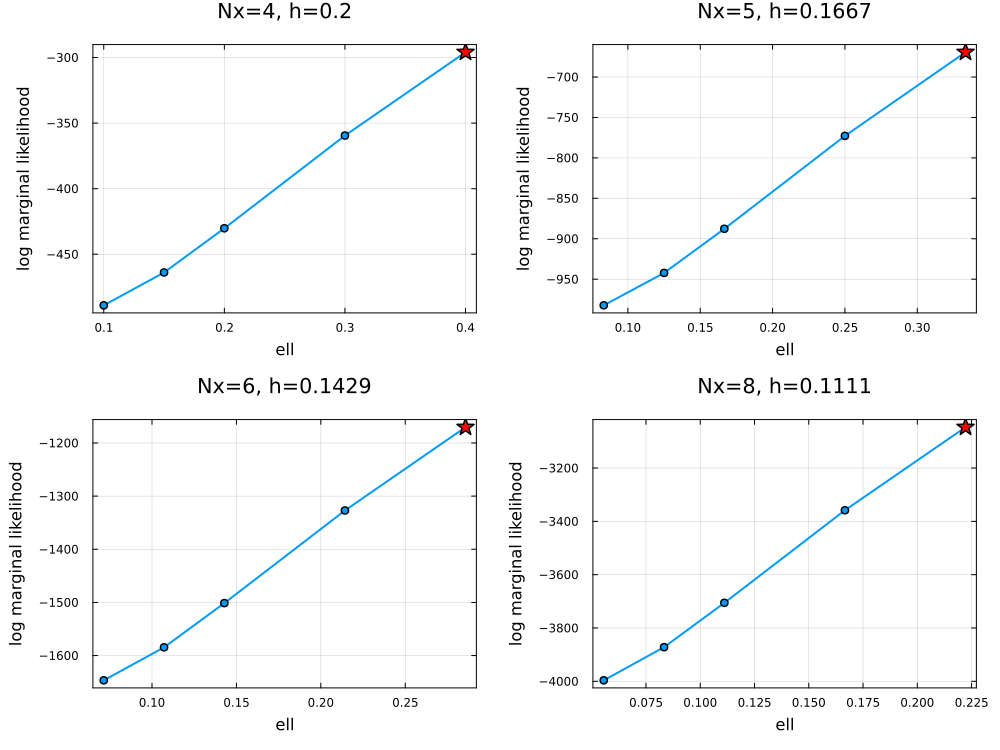

"/Users/shoji/Project_with_Jon/Helmholtz_arranged/helmholtz3d_Nx_sweep_ell_lml.png"

In [12]:
# ============================================================
# ell-LML diagnostics
# ============================================================

plots_ell = []

for r in results_Nx

    p = plot(
        r.ell_grid,
        r.lml;
        marker=:circle,
        lw=2,
        xlabel="ell",
        ylabel="log marginal likelihood",
        title="Nx=$(r.Nx), h=$(round(r.h,sigdigits=4))",
        label=false,
        framestyle=:box
    )

    scatter!(
        p,
        [r.ell],
        [maximum(r.lml)];
        marker=:star5,
        markersize=9,
        color=:red,
        label=false
    )

    push!(plots_ell,p)
end

fig_ell = plot(
    plots_ell...;
    layout=(2,2),
    size=(1000,750),
    margin=4*Plots.mm
)

display(fig_ell)

savefig(
    fig_ell,
    "helmholtz3d_Nx_sweep_ell_lml.png"
)
